# Test comparison

LEAR, DNN and TFT on the test year, 2025-10-20 to 2026-10-18 (364 days). Nothing is retrained here. The forecasts are the ones already saved by the backtests, scored against `PL_price` in EUR/MWh. Lower is better.

The notebook has two parts.

**1. TFT.** Each feature set has one trial carried into the backtest: trial 112 for `D1`, 93 for `D2` and 112 for `D3`. Each trial was trained on seeds 1–5. Two forecasts are kept per step. One is the seed with the lowest test MAE, named `<step> s<n>`. The other is the mean of the five seed forecasts, named `<step> ens`. These six forecasts are compared by metrics and by the DM and GW tests, to decide whether the seed or the ensemble is used further.

**2. TFT ensembles against LEAR and DNN.** Only the three TFT ensembles go on, as `TFT D1`, `TFT D2` and `TFT D3`. LEAR is `LEAR_1092` and DNN is `DNN_3`, both on the base exogenous inputs. This part has the metrics, the DM and GW tests and the error profiles by hour, weekday and month for those five forecasts.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

import pandas as pd

from src.config import BASE_DIR
from src.utils.evaluation import compare_models, score_forecast
from src.utils.file_io import load_final_dataset
from src.utils.plots import plot_cumulative, plot_profile, plot_tests

SEED_COLS = ["1", "2", "3", "4", "5"]
TFT_TRIALS = {"d1": 112, "d2": 93, "d3": 112}
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def read_forecast(path):
    return pd.read_csv(path, index_col=0, parse_dates=True)


## 1. TFT: best seed and ensemble

### Seeds

The five seeds of a step are separate trainings of the same trial. The table is the test MAE of each seed, and `ensemble` is the MAE of the mean of the five forecasts. That last column is not the mean of the five MAEs. The lowest seed in a row is the one named `<step> s<n>` below.

In [2]:
prices = load_final_dataset("base", "pl", "test")["PL_price"]

tft = {}
ensembles = {}
seed_rows = {}
for step, trial in TFT_TRIALS.items():
    raw = read_forecast(
        BASE_DIR / "results" / "tft" / step / "test" / f"trial_{trial}.csv"
    )
    raw.columns = [str(col) for col in raw.columns]
    row = {
        seed: score_forecast(prices, raw[[seed]], metrics=["MAE"])["MAE"]
        for seed in SEED_COLS
    }
    ensemble = raw[SEED_COLS].mean(axis=1)
    row["ensemble"] = score_forecast(prices, ensemble.to_frame("ens"), metrics=["MAE"])[
        "MAE"
    ]
    best = min(SEED_COLS, key=row.get)
    label = step.upper()
    seed_rows[label] = row
    tft[f"{label} s{best}"] = raw[best]
    tft[f"{label} ens"] = ensemble
    ensembles[f"TFT {label}"] = ensemble

tft_forecasts = pd.DataFrame(tft)
seed_mae = pd.DataFrame(seed_rows).T[SEED_COLS + ["ensemble"]]
seed_mae.round(3)

,1,2,3,4,5,ensemble
D1,25.943,25.491,23.802,24.707,25.534,23.394
D2,21.020,20.135,21.595,20.423,20.774,19.008
D3,20.733,19.980,20.762,20.365,20.023,18.855


On `D1` seed 3 stands apart at 23.802. The other four sit between 24.707 and 25.943, and the ensemble improves on seed 3 by only 0.408, to 23.394. On `D2` seed 2 is lowest at 20.135 and seed 1 is the weak one at 21.020. On `D3` seeds 2 and 5 are close, 19.980 and 20.023, and seed 2 is the one named below. The ensembles of `D2` and `D3` drop further, to 19.008 and 18.855.

### Metrics

MAE and RMSE are in EUR/MWh. rMAE divides the MAE by the MAE of a naive forecast that repeats the price from the same hour a week earlier, so a value below 1 beats that naive forecast. The table is ordered by MAE.

In [3]:
compare_models(
    tft_forecasts, prices, metrics=["rMAE", "MAE", "RMSE", "sMAPE"]
).sort_values("MAE").round(3)

,rMAE,MAE,RMSE,sMAPE
model,,,,
D3 ens,0.508,18.855,31.417,0.252
D2 ens,0.513,19.008,31.813,0.258
D3 s2,0.539,19.980,32.559,0.263
D2 s2,0.543,20.135,33.199,0.270
D1 ens,0.631,23.394,36.917,0.294
D1 s3,0.642,23.802,38.389,0.301


In every step the ensemble has a lower MAE than that step's best seed: by 0.408 on `D1`, 1.127 on `D2` and 1.125 on `D3`. The `D3` and `D2` ensembles lead at 18.855 and 19.008, and both are ahead of the best single seed of either step, 19.980 for `D3` and 20.135 for `D2`. So averaging five seeds moves a forecast further than the move from `D2` to `D3` does for a single seed.

rMAE, RMSE and sMAPE all keep this order.

### DM and GW tests

Both tests use the daily absolute errors, with all 24 hours of a day tested jointly. DM tests whether one forecast is more accurate than the other on average. GW is its conditional version, which also takes the previous day's loss difference into account.

Each cell is the p-value of the one-sided test that the forecast on the x-axis is more accurate than the forecast on the y-axis. Green and yellow (p < 0.05) mean a significant difference, red (0.05–0.10) is borderline, and black (p > 0.10) means the two forecasts cannot be told apart.

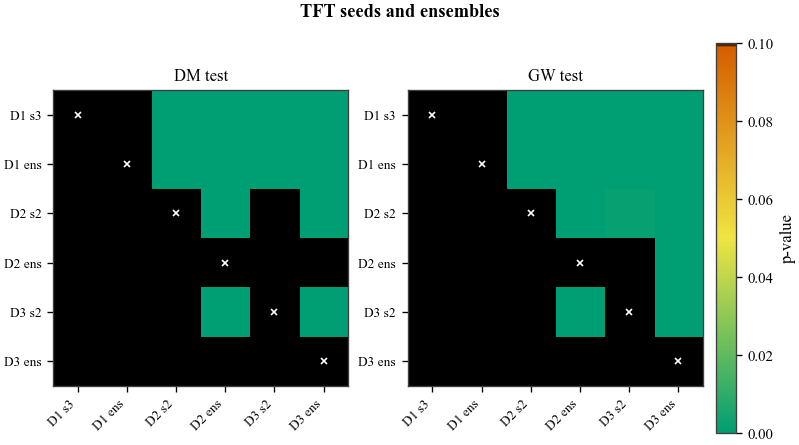

In [4]:
plot_tests(tft_forecasts, prices, "TFT seeds and ensembles")

Within `D2` and `D3`, both tests favour the ensemble over the best seed. They do not separate the `D1` ensemble from its best seed, consistent with their small MAE difference.

Both tests favour the `D2` and `D3` forecasts over those from `D1`. Neither test shows a forecast significantly better than `D3 ens`. DM does not distinguish `D2 ens` from `D3 ens`, while GW favours `D3 ens`.

Each ensemble has a lower MAE than its best seed in the table, so the comparison with LEAR and DNN uses the three ensembles.

## 2. TFT ensembles against LEAR and DNN

### Metrics

The table compares the three TFT ensembles with LEAR and DNN using rMAE, MAE and RMSE.

In [5]:
forecasts = pd.DataFrame(
    {
        "LEAR": read_forecast(
            BASE_DIR / "results" / "lear" / "test" / "full" / "LEAR_1092.csv"
        ).iloc[:, 0],
        "DNN": read_forecast(
            BASE_DIR / "results" / "dnn" / "test" / "full" / "DNN_3.csv"
        ).iloc[:, 0],
        **ensembles,
    }
)

compare_models(forecasts, prices, metrics=["rMAE", "MAE", "RMSE"]).sort_values(
    "MAE"
).round(3)

,rMAE,MAE,RMSE
model,,,
TFT D3,0.508,18.855,31.417
TFT D2,0.513,19.008,31.813
LEAR,0.587,21.783,34.823
DNN,0.605,22.447,36.404
TFT D1,0.631,23.394,36.917


All three metrics give the same order: `TFT D3`, `TFT D2`, LEAR, DNN, `TFT D1`. `TFT D3` has MAE 18.855, which is 2.928 below LEAR at 21.783 and 3.592 below DNN at 22.447. `TFT D2` is at 19.008. The `D1` ensemble, at 23.394, is 1.611 above LEAR and 0.947 above DNN. Every forecast has an rMAE below 1, from 0.508 for `TFT D3` to 0.631 for `TFT D1`, so all of them beat the naive weekly forecast.

### DM and GW tests

Read in the same way as above, now for the five forecasts.

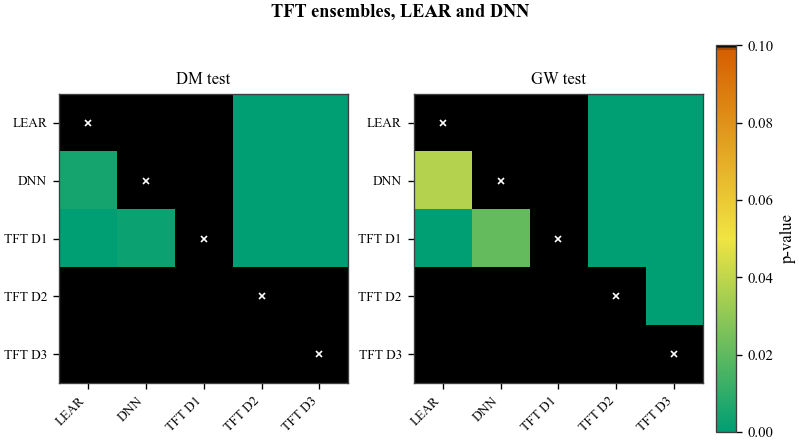

In [6]:
plot_tests(forecasts, prices, "TFT ensembles, LEAR and DNN")

Both tests favour `TFT D2` and `TFT D3` over LEAR, DNN and `TFT D1`. DM does not distinguish the two leading TFT ensembles, while GW favours `TFT D3`.

LEAR is favoured over DNN, and DNN over `TFT D1`, by both tests. The same tests favour LEAR over `TFT D1`.

### Error profiles

Each profile shows mean absolute error against `PL_price` for the five forecasts, grouped by hour, weekday or month.

In [7]:
err = forecasts.sub(prices, axis=0).abs()
idx = err.index
by_hour = err.groupby(idx.hour).mean()
by_dow = err.groupby(idx.dayofweek).mean()
by_dow.index = DOW
by_month = err.groupby(idx.to_period("M")).mean()
by_month.index = by_month.index.astype(str)

#### Hour

Hours 0–5 are the easy part of the day. LEAR averages 10.72 over those six hours and DNN 10.98, against 11.45 for `TFT D3`, 11.61 for `TFT D2` and 13.59 for `TFT D1`. LEAR is the lowest line at hours 0–4, and at hour 5 `TFT D2`, at 11.51, edges just under LEAR's 11.72. From hour 6 to hour 23 `TFT D2` and `TFT D3` are below both LEAR and DNN at every hour.

The error climbs through the morning. Four of the five forecasts peak at hour 13: `TFT D1` at 33.85, LEAR at 32.19, `TFT D2` at 29.64 and `TFT D3` at 27.76. DNN peaks at hour 20 instead, at 33.41. Hours 19–20 are a second rise for every forecast, followed by a drop at hour 21. `TFT D2` is the lowest line at hours 6–7, 15–17 and 20–23, and `TFT D3` at hours 8–14 and 18–19.

LEAR is below DNN at every hour except 6, 7, 10 and 14, where DNN is lower instead. From hour 8 to hour 20 `TFT D1` stays within about 2 EUR/MWh of LEAR. At night it is the highest line.

In [8]:
by_hour.round(2)

,LEAR,DNN,TFT D1,TFT D2,TFT D3
0,8.92,9.56,12.87,11.82,10.90
1,9.90,10.41,12.74,11.35,10.99
2,11.06,11.10,13.66,11.64,11.38
3,11.19,11.33,13.61,11.69,11.44
4,11.53,11.61,14.01,11.64,11.87
5,11.72,11.85,14.65,11.51,12.14
6,15.20,14.72,18.51,13.40,13.97
7,20.24,20.12,21.86,16.95,17.68
8,22.55,24.03,23.52,19.32,18.43
9,24.82,25.02,25.36,20.46,19.15


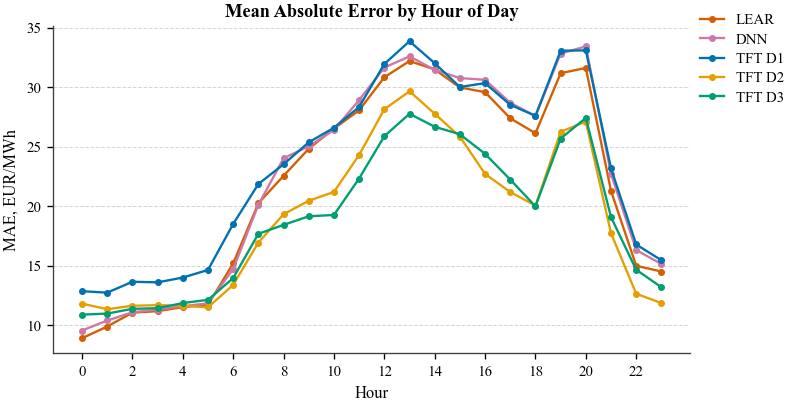

In [9]:
plot_profile(
    by_hour,
    xlabel="Hour",
    xticks=range(0, 24, 2),
    title="Mean Absolute Error by Hour of Day",
)

#### Weekday

Monday is the hardest day for every forecast: 21.57 for `TFT D2`, 21.66 for `TFT D3`, 25.32 for LEAR, 26.00 for DNN and 27.70 for `TFT D1`. The easiest day is Saturday for LEAR, DNN, `TFT D2` and `TFT D3`, and Sunday for `TFT D1`.

`TFT D2` is the lowest line on Monday, Tuesday, Wednesday and Friday, and `TFT D3` on Thursday, Saturday and Sunday. On Monday the two are 0.09 apart. Both are below LEAR and DNN on every weekday, by the smallest margin on Sunday, 18.40 and 17.98 against 19.38 (LEAR) and 19.91 (DNN). `TFT D1` is above both LEAR and DNN on every weekday. LEAR is below DNN on every weekday too, narrowest on Sunday (19.38 against 19.91).

In [10]:
by_dow.round(2)

,LEAR,DNN,TFT D1,TFT D2,TFT D3
Mon,25.32,26.00,27.70,21.57,21.66
Tue,24.24,24.60,24.86,21.00,21.15
Wed,21.69,22.72,23.30,17.78,18.08
Thu,22.28,22.89,23.68,19.30,18.78
Fri,20.24,21.50,22.75,17.74,17.91
Sat,19.33,19.51,20.81,17.27,16.43
Sun,19.38,19.91,20.66,18.40,17.98


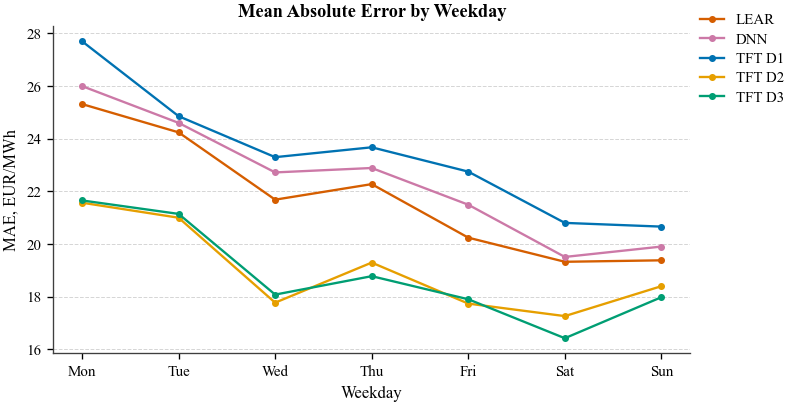

In [11]:
plot_profile(
    by_dow,
    xlabel="Weekday",
    title="Mean Absolute Error by Weekday",
)

#### Month

October 2025 covers only 20–31 October and October 2026 only 1–18 October, so those two points rest on fewer days. February is the easiest month for every forecast: 10.09 for `TFT D3`, 11.40 for `TFT D2`, 11.54 for DNN, 11.87 for LEAR and 13.85 for `TFT D1`. January is high for every forecast, from 23.18 for `TFT D3` to 30.98 for `TFT D1`. September 2026 is the hardest month for LEAR and the three TFT configurations (29.57, 33.39, 29.98 and 33.09), while DNN's hardest month is January 2026 instead (29.37), only marginally above its September value (29.02). In September, DNN is the lowest line at 29.02, just under LEAR's 29.57, with `TFT D2` at 29.98. In July `TFT D3`, at 22.40, is behind `TFT D2` (19.33), DNN (20.24), `TFT D1` (20.80) and LEAR (21.29).

`TFT D3` is the lowest line in December, January, February, March, April and June. `TFT D2` is the lowest in October 2025, November, May, July, August and October 2026. DNN is the lowest only in September. Neither LEAR nor `TFT D1` is the lowest line in any month.

In [12]:
by_month.round(2)

,LEAR,DNN,TFT D1,TFT D2,TFT D3
2025-10,20.68,22.57,23.98,11.60,12.39
2025-11,19.84,22.11,21.22,15.34,15.86
2025-12,14.26,15.02,15.04,14.15,12.10
2026-01,28.74,29.37,30.98,24.17,23.18
2026-02,11.87,11.54,13.85,11.40,10.09
2026-03,20.35,20.95,21.47,17.33,14.83
2026-04,23.74,25.35,24.75,20.26,17.68
2026-05,19.82,20.97,20.87,15.88,16.10
2026-06,22.94,23.15,22.35,19.94,17.87
2026-07,21.29,20.24,20.80,19.33,22.40


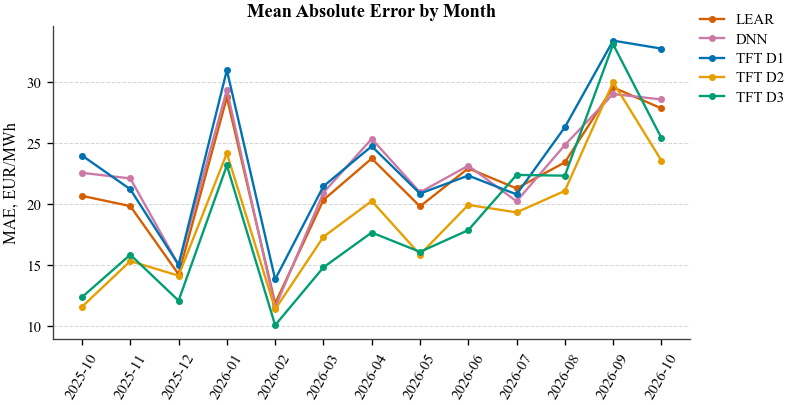

In [13]:
plot_profile(
    by_month,
    rotation=60,
    title="Mean Absolute Error by Month",
)

#### Cumulative absolute error

LEAR and DNN are refit daily, while the TFT ensembles use fixed models throughout the test period. The cumulative absolute error chart shows how each forecast's errors add up over time. The table below compares mean errors in the first and second halves of the test year.

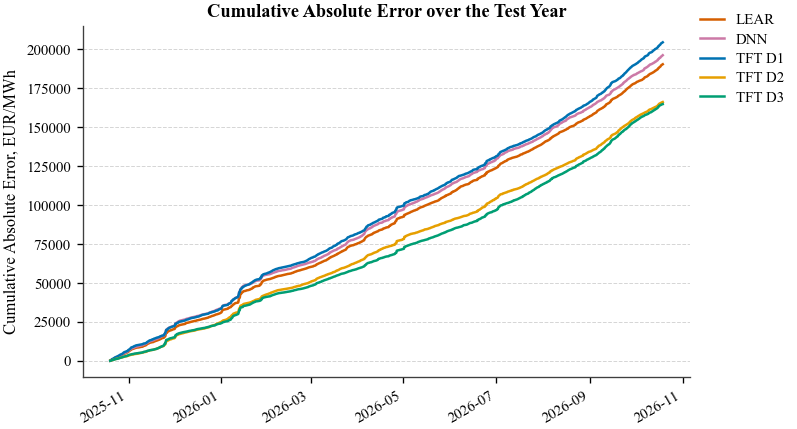

In [14]:
cae = err.cumsum()
fig = plot_cumulative(
    cae,
    title="Cumulative Absolute Error over the Test Year",
)
fig

In [15]:
mid = idx.min() + (idx.max() - idx.min()) / 2
halves = pd.concat(
    {
        "H1 MAE": err.loc[idx < mid].mean(),
        "H2 MAE": err.loc[idx >= mid].mean(),
    },
    axis=1,
)
halves["H2 - H1"] = halves["H2 MAE"] - halves["H1 MAE"]
ref = err[["LEAR", "DNN"]].mean(axis=1)
halves["vs LEAR/DNN, H1"] = err.loc[idx < mid].mean() / ref.loc[idx < mid].mean()
halves["vs LEAR/DNN, H2"] = err.loc[idx >= mid].mean() / ref.loc[idx >= mid].mean()
halves.round(3)

,H1 MAE,H2 MAE,H2 - H1,"vs LEAR/DNN, H1","vs LEAR/DNN, H2"
LEAR,19.594,23.973,4.379,0.975,0.994
DNN,20.616,24.279,3.663,1.025,1.006
TFT D1,21.231,25.558,4.327,1.056,1.059
TFT D2,16.704,21.312,4.609,0.831,0.883
TFT D3,15.320,22.390,7.070,0.762,0.928


The cumulative curves show `TFT D2` and `TFT D3` building a lead early in the test year. In the second half, their advantage over LEAR and DNN grows more slowly.

The half-year table makes that change clearer. Relative to the LEAR/DNN average, `TFT D3` rises from 0.762 in H1 to 0.928 in H2; `TFT D2` rises from 0.831 to 0.883. The corresponding ratio for `TFT D1` stays near 1.06 in both halves. `TFT D2` and `TFT D3` still have lower MAE than either reference model in H2, but by a smaller margin than in H1.

Over this test year, `TFT D2` and `TFT D3` retain the lowest overall MAE despite their smaller relative advantage in the second half. The chart and table show the change in performance over time; they do not isolate the effect of retraining frequency.

## Conclusions

Among the TFT forecasts the ensemble is the better choice in every step. Averaging the five seeds lowers the MAE by about 1.1 EUR/MWh on `D2` and `D3`, and by 0.4 on `D1`; on `D2` and `D3` that gain is significant under DM and GW.

Against LEAR and DNN the ranking follows the feature set. `TFT D3` has the lowest MAE, 18.855, and `TFT D2` is next at 19.008. Both are significantly more accurate than LEAR (21.783) and DNN (22.447), and DM does not separate them while GW prefers `TFT D3`. LEAR is significantly more accurate than DNN, which in turn is significantly more accurate than `TFT D1` (23.394) - the weakest of the five forecasts.

The error profiles put `TFT D2` and `TFT D3` in front almost everywhere. The exceptions are the early-morning hours, where LEAR is the lowest line through hour 4, and September, where DNN edges ahead. `TFT D3` is ahead in the months from December to April and in June. `TFT D2` is ahead in October 2025, November, May, July, August and October 2026, and `TFT D3` falls behind all four other forecasts in July.

The cumulative error chart and half-year table add one qualification: `TFT D2` and `TFT D3` have a smaller lead over LEAR and DNN in the second half, although their overall MAE remains lower. This comparison does not establish why the lead narrows.